# Robust Regression & Outlier Handling in Quantitative Finance
## A Methodological and Econometric Guide to High-Breakdown Estimation

---

### Executive Summary & Research Question

**Research Question:**  
*How to reliably detect, model, and mitigate the impact of outliers in linear regression parameter estimation across both cross-sectional batch analysis and dynamic time-series / streaming environments?*

In financial econometrics and quantitative trading, return and spread distributions consistently display **heavy tails (leptokurtosis)**, discrete regime shifts, structural breaks, liquidity micro-structure dislocations, and data recording errors (bad ticks). The naive application of Ordinary Least Squares (**OLS**) results in severe parameter distortions--such as biased market $\beta$ sensitivities or unstable cointegration hedge ratios--leading to flawed portfolio construction, erratic rebalancing, and unhedged risk exposure.

This research addresses the question through a rigorous two-part framework:
1. **Part 1 -- Static Batch Estimation:** Comparative analysis of OLS, MAD-based Winsorized OLS, Iteratively Reweighted Least Squares (IRLS with Huber M-estimator), Theil-Sen, and RANSAC under an adversarial local bad-leverage outlier cluster. We demonstrate why contaminated in-sample RMSE is a misleading metric and validate estimator distributions via a Monte Carlo simulation ($M = 200$).
2. **Part 2 -- Adaptive Online Estimation:** Evaluation of Rolling OLS (fixed trailing window), Standard Kalman Filter (infinite exponential memory), and an explicit **Robust Kalman Filter (Huber-dampened innovation)** engineered to reject transient anomalies in real-time streaming data.

---

### Outlier Taxonomy in Quantitative Finance

| Outlier Type | Econometric Definition | Financial Consequence | Recommended Treatment |
|:---|:---|:---|:---|
| **Vertical Outliers** | Anomalies purely in the dependent variable $y$ | Inflates residual variance $\sigma^2$, biases the intercept $\beta_0$ | M-Estimators (Huber/Bisquare), Winsorization |
| **Good Leverage Points** | Extreme in feature space $x$, but consistent with the true linear manifold | Reduces parameter standard errors, preserves slope | Retain in estimation set |
| **Bad Leverage Points** | Extreme in feature space $x$ with high vertical residual | Severely rotates the regression slope $\beta_1$ and shifts intercept | High-breakdown estimators (RANSAC, Theil-Sen) |
| **Regime Shifts / Clusters** | Temporally or spatially correlated pockets of anomalies | Causes window-exit shocks in rolling models and filter divergence | Robust Kalman Filter, Markov-Switching models |

---

### Batch Estimator Methodology Matrix

| Estimator | Optimization Objective | Breakdown Point | Gaussian Efficiency | Primary Quantitative Use Case |
|:---|:---|:---:|:---:|:---|
| **OLS** | $\min_\beta \sum r_i^2$ | **0%** (1 point suffices) | 100% (BLUE) | Benchmark under strict i.i.d. Gaussian assumptions |
| **Winsorized OLS (MAD)** | $\min_\beta \sum (\tilde{y}_i - X_i\beta)^2$ via MAD clamping | Threshold-dependent (~5%) | High | Standard in multi-factor equity models (Barra, Axioma) |
| **IRLS (Huber M-Est.)** | $\min_\beta \sum \rho_k(r_i)$ via weights $w_i(r_i)$ | **0%** (leverage), **50%** (vertical) | 95% (with $k=1.345$) | Market Beta estimation, yield curve term structure fitting |
| **Theil-Sen** | Median of pairwise slopes | **~29.3%** | ~64% | Non-parametric bivarate regression, robust trendlines |
| **RANSAC** | Maximize inlier consensus cardinality | **up to 50%** | Variable (hard rejection) | High-noise signal extraction, tick-data anomaly filtering |


## Setup

We initialize numerical packages and configure Matplotlib aesthetics to adhere to publication-grade quantitative research standards.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from IPython.display import display

# Visualization settings
warnings.filterwarnings('ignore')
plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'figure.titlesize': 14
})

# Harmonized color palette across estimators
COLORS = {
    'clean': '#1F3A60',          # Deep Navy for regular inliers
    'outlier': '#D9381E',        # Crimson Red for outliers
    'true': '#111111',           # Charcoal Black for Ground Truth
    'ols': '#D9381E',            # Crimson for biased OLS
    'winsor': '#E67E22',         # Amber Orange for Winsorized OLS
    'irls': '#6C3483',           # Royal Purple for IRLS Huber
    'theilsen': '#2980B9',       # Cobalt Blue for Theil-Sen
    'ransac': '#27AE60',         # Emerald Green for RANSAC
    'kalman': '#16A085',         # Teal for Standard Kalman
    'robust_kalman': '#8E44AD'   # Deep Violet for Robust Kalman
}

print("Environment configured successfully.")


Environment configured successfully.


## Data Generating Process

We specify a ground-truth linear DGP:

$$y_t = \beta_0^* + \beta_1^* \cdot x_t + \varepsilon_t, \quad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$

with underlying structural parameters:
* $\beta_0^* = 2.0$ (true intercept)
* $\beta_1^* = 1.5$ (true slope / sensitivity)
* Gaussian error $\sigma = 1.0$ across $N = 1000$ observations.

### Generating an Adversarial Leverage Cluster
Rather than introducing isolated, randomly dispersed outliers, we inject an adversarial cluster of **$N_{\text{out}} = 50$ observations (5.0% of the sample)** localized around $x \approx 1.0$ (semi-bandwidth $\pm 0.6$).
This simultaneously creates:
1. **High Leverage Coordinates ($h_{ii}$):** Observations located away from the sample center $\bar{x} = 0$, giving them strong structural pull.
2. **Substantial Vertical Displacement (offset $\approx +13.0$, $\sigma_{\text{out}} = 4.0$):** Incompatible with the true data-generating manifold.


Total Sample Size: N = 1000
Contaminated Outliers: N_out = 50 (5.0% of dataset)
Ground Truth Parameters: beta_0 = 2.00, beta_1 = 1.50
Mean Leverage h_ii: 0.0020 | Alert Leverage Threshold (2p/N): 0.0040
Mean Leverage of Outlier Cluster: 0.0014


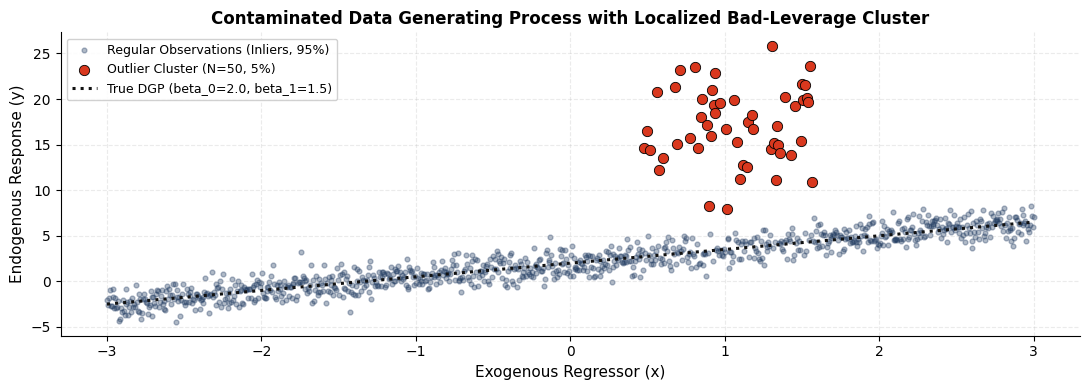

In [2]:
np.random.seed(42)

N = 1000
N_OUT = 50  # Exactly 5.0% of sample size
BETA0_TRUE = 2.0
BETA1_TRUE = 1.5

# Exogenous regressor grid and standard i.i.d. noise
x = np.linspace(-3.0, 3.0, N)
eps = np.random.normal(0.0, 1.0, N)
y_clean = BETA0_TRUE + BETA1_TRUE * x + eps

# Injection of an adversarial bad-leverage cluster
out_x_center = 1.0
out_x_window = 0.6
out_y_offset = 13.0
out_y_spread = 4.0

candidate_idx = np.where(np.abs(x - out_x_center) < out_x_window)[0]
out_idx = np.random.choice(candidate_idx, N_OUT, replace=False)

y_dirty = y_clean.copy()
y_line_at_cluster = BETA0_TRUE + BETA1_TRUE * x[out_idx]
y_dirty[out_idx] = y_line_at_cluster + out_y_offset + np.random.normal(0.0, out_y_spread, N_OUT)

is_out = np.zeros(N, dtype=bool)
is_out[out_idx] = True

# Design matrix X with column of ones
X = np.column_stack([np.ones(N), x])

# Leverage diagnostics via Hat Matrix H = X(X^T X)^(-1) X^T
H = X @ np.linalg.inv(X.T @ X) @ X.T
leverage_h = np.diag(H)
leverage_threshold = 2.0 * X.shape[1] / N  # Standard rule of thumb: 2p/N

print(f"Total Sample Size: N = {N}")
print(f"Contaminated Outliers: N_out = {N_OUT} ({N_OUT/N:.1%} of dataset)")
print(f"Ground Truth Parameters: beta_0 = {BETA0_TRUE:.2f}, beta_1 = {BETA1_TRUE:.2f}")
print(f"Mean Leverage h_ii: {leverage_h.mean():.4f} | Alert Leverage Threshold (2p/N): {leverage_threshold:.4f}")
print(f"Mean Leverage of Outlier Cluster: {leverage_h[is_out].mean():.4f}")

# Exploratory scatter plot of contaminated data
fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(x[~is_out], y_dirty[~is_out], color=COLORS['clean'], alpha=0.35, s=12, label='Regular Observations (Inliers, 95%)')
ax.scatter(x[is_out], y_dirty[is_out], color=COLORS['outlier'], s=55, edgecolor='black', linewidth=0.6, zorder=5, label=f'Outlier Cluster (N={N_OUT}, 5%)')
x_grid = np.linspace(x.min(), x.max(), 300)
ax.plot(x_grid, BETA0_TRUE + BETA1_TRUE * x_grid, color=COLORS['true'], lw=2.2, ls=':', label=f'True DGP (beta_0={BETA0_TRUE}, beta_1={BETA1_TRUE})')
ax.set_title('Contaminated Data Generating Process with Localized Bad-Leverage Cluster', fontweight='bold')
ax.set_xlabel('Exogenous Regressor (x)')
ax.set_ylabel('Endogenous Response (y)')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


## PART 1: Static Batch Estimation

We implement and evaluate five distinct estimation approaches to neutralize the outlier cluster:

---

### OLS
Minimizes the sum of squared residuals:

$$\hat{\beta}_{\text{OLS}} = \arg\min_\beta \sum_{t=1}^N (y_t - X_t \beta)^2 = (X^T X)^{-1} X^T y$$

The quadratic loss function weights an outlier with $r_i = 15$ by a factor of $15^2 = 225$ relative to an inlier with $r_i = 1$. Its theoretical breakdown point is **0%**.

---

### Winsorized OLS
In commercial multi-factor equity risk models (e.g., Barra, Axioma), cross-sectional variables are winsorized via the Median Absolute Deviation (**MAD**):

$$\tilde{y}_t = \text{clip}\left(y_t, \; \text{Med}(y) - k \cdot \hat{\sigma}_{\text{MAD}}, \; \text{Med}(y) + k \cdot \hat{\sigma}_{\text{MAD}}\right)$$

The scale estimator $\hat{\sigma}_{\text{MAD}} = \frac{\text{median}(|y - \text{median}(y)|)}{0.6745}$ provides a consistent estimate of the standard deviation under normality.

---

### IRLS (Huber)
Replaces the $L_2$ loss with the hybrid Huber loss function $\rho_k(r)$:

$$\rho_k(r) = \begin{cases} \frac{1}{2} r^2 & \text{if } |r| \leq k\hat{\sigma} \\ k\hat{\sigma} |r| - \frac{1}{2} (k\hat{\sigma})^2 & \text{if } |r| > k\hat{\sigma} \end{cases}$$

Optimized iteratively with data-dependent weights $w_i = \min\left(1, \frac{k\hat{\sigma}}{|r_i|}\right)$. With $k = 1.345$, the estimator preserves **95% asymptotic efficiency** under Gaussianity while downgrading extreme residual penalties from quadratic to linear.

---

### Theil-Sen
A non-parametric estimator defined by the median of all pairwise bivariate slopes:

$$\hat{\beta}_1 = \text{median}\left( \left\{ \frac{y_j - y_i}{x_j - x_i} \;\middle|\; x_i \neq x_j \right\} \right), \quad \hat{\beta}_0 = \text{median}(y - \hat{\beta}_1 x)$$

Provides an asymptotic breakdown point of **~29.3%** and is resilient against severe asymmetric distortions.

---

### RANSAC
An iterative non-deterministic algorithm based on minimal sample consensus:
1. Randomly sample 2 points to fit a candidate hypothesis line.
2. Quantify inliers whose absolute residual is within an automated threshold $\tau = 3 \cdot \hat{\sigma}_{\text{MAD}}$.
3. Retain the model that maximizes the inlier consensus set.
4. Perform an OLS refit **strictly on the consensus inlier subset**. Theoretical breakdown point reaches up to **50%**.








In [3]:
# ------------------------------------------------------------------------------
# 2.1 Standard OLS
# ------------------------------------------------------------------------------
beta_ols = np.linalg.lstsq(X, y_dirty, rcond=None)[0]
b0_ols, b1_ols = beta_ols
r_ols = y_dirty - (b0_ols + b1_ols * x)

# ------------------------------------------------------------------------------
# 2.2 MAD-Based Winsorized OLS
# ------------------------------------------------------------------------------
def fit_winsorized_ols(x_arr, y_arr, k_mad=3.0):
    med_y = np.median(y_arr)
    mad_y = np.median(np.abs(y_arr - med_y)) / 0.6745
    lower_bound = med_y - k_mad * mad_y
    upper_bound = med_y + k_mad * mad_y
    y_win = np.clip(y_arr, lower_bound, upper_bound)
    X_mat = np.column_stack([np.ones(len(x_arr)), x_arr])
    beta_win = np.linalg.lstsq(X_mat, y_win, rcond=None)[0]
    return beta_win, y_win

beta_win, y_winsorized = fit_winsorized_ols(x, y_dirty, k_mad=3.0)
b0_win, b1_win = beta_win
r_win = y_dirty - (b0_win + b1_win * x)

# ------------------------------------------------------------------------------
# 2.3 IRLS with Huber M-Estimator
# ------------------------------------------------------------------------------
def fit_irls_huber(X_mat, y_arr, k=1.345, max_iter=100, tol=1e-8):
    beta = np.linalg.lstsq(X_mat, y_arr, rcond=None)[0]
    w = np.ones(len(y_arr))
    for it in range(max_iter):
        r = y_arr - X_mat @ beta
        sigma_mad = np.median(np.abs(r)) / 0.6745
        u = np.abs(r) / (k * sigma_mad + 1e-12)
        w = np.where(u <= 1.0, 1.0, 1.0 / u)
        
        # Weighted Least Squares step
        W_half = np.sqrt(w)[:, None]
        X_w = X_mat * W_half
        y_w = y_arr * np.sqrt(w)
        beta_next = np.linalg.lstsq(X_w, y_w, rcond=None)[0]
        
        if np.max(np.abs(beta_next - beta)) < tol:
            break
        beta = beta_next
    return beta, w, it + 1

beta_irls, w_final, irls_iters = fit_irls_huber(X, y_dirty, k=1.345)
b0_irls, b1_irls = beta_irls
r_irls = y_dirty - (b0_irls + b1_irls * x)

# ------------------------------------------------------------------------------
# 2.4 Theil-Sen Estimator (Vectorized Subsampling for Computational Efficiency)
# ------------------------------------------------------------------------------
def fit_theil_sen(x_arr, y_arr, max_pairs=100000, rng_seed=42):
    n = len(x_arr)
    rng = np.random.default_rng(rng_seed)
    idx_i = rng.integers(0, n, max_pairs)
    idx_j = rng.integers(0, n, max_pairs)
    valid = idx_i != idx_j
    idx_i, idx_j = idx_i[valid], idx_j[valid]
    dx = x_arr[idx_j] - x_arr[idx_i]
    non_zero = np.abs(dx) > 1e-9
    dx = dx[non_zero]
    dy = y_arr[idx_j[non_zero]] - y_arr[idx_i[non_zero]]
    slopes = dy / dx
    slope_med = np.median(slopes)
    intercept_med = np.median(y_arr - slope_med * x_arr)
    return np.array([intercept_med, slope_med])

beta_theilsen = fit_theil_sen(x, y_dirty)
b0_ts, b1_ts = beta_theilsen
r_ts = y_dirty - (b0_ts + b1_ts * x)

# ------------------------------------------------------------------------------
# 2.5 RANSAC Regression
# ------------------------------------------------------------------------------
def fit_ransac(X_mat, y_arr, n_iter=1000, residual_threshold=None, rng_seed=42):
    rng = np.random.default_rng(rng_seed)
    n = X_mat.shape[0]
    
    # Automatic robust threshold via MAD of initial residuals
    if residual_threshold is None:
        b_init = np.linalg.lstsq(X_mat, y_arr, rcond=None)[0]
        r_init = y_arr - X_mat @ b_init
        residual_threshold = 3.0 * (np.median(np.abs(r_init - np.median(r_init))) / 0.6745)
        
    best_inliers = None
    best_count = -1
    best_beta = None
    
    for _ in range(n_iter):
        idx = rng.choice(n, size=2, replace=False)
        try:
            b_sample = np.linalg.lstsq(X_mat[idx], y_arr[idx], rcond=None)[0]
        except np.linalg.LinAlgError:
            continue
        res = np.abs(y_arr - X_mat @ b_sample)
        inliers = res < residual_threshold
        count = np.sum(inliers)
        if count > best_count:
            best_count = count
            best_inliers = inliers
            best_beta = b_sample
            
    # Final OLS refit on the identified consensus set
    beta_refined = np.linalg.lstsq(X_mat[best_inliers], y_arr[best_inliers], rcond=None)[0]
    return beta_refined, best_inliers, residual_threshold

beta_ransac, inliers_ransac, tau_ransac = fit_ransac(X, y_dirty, n_iter=1000)
b0_ransac, b1_ransac = beta_ransac
r_ransac = y_dirty - (b0_ransac + b1_ransac * x)

print("Batch model estimation completed successfully.")


Batch model estimation completed successfully.


## Performance Benchmark

### The Contaminated In-Sample RMSE Paradox
A critical pitfall in quantitative modeling is evaluating estimator quality via in-sample root mean squared error on the contaminated dataset ($RMSE_{\text{dirty}}$).  
Because **OLS is mathematically constrained to minimize this exact quantity**, it will artificially report the lowest $RMSE_{\text{dirty}}$, while severely distorting the structural slope!

The statistically sound evaluation criteria are:
1. **Parameter Bias:** $\text{Bias}(\beta_0) = |\hat{\beta}_0 - \beta_0^*|$ and $\text{Bias}(\beta_1) = |\hat{\beta}_1 - \beta_1^*|$
2. **Total Parameter Loss:** $\|\hat{\beta} - \beta^*\|_2 = \sqrt{(\hat{\beta}_0 - \beta_0^*)^2 + (\hat{\beta}_1 - \beta_1^*)^2}$
3. **Out-of-Sample / Clean RMSE ($RMSE_{\text{clean}}$):** Prediction error evaluated strictly on the 95% regular inlier observations.


In [4]:
# Quantitative performance metric computation
def compute_metrics(b0, b1, y_obs, is_out_mask):
    b_err = np.sqrt((b0 - BETA0_TRUE)**2 + (b1 - BETA1_TRUE)**2)
    y_pred = b0 + b1 * x
    rmse_dirty = np.sqrt(np.mean((y_obs - y_pred)**2))
    rmse_clean = np.sqrt(np.mean((y_obs[~is_out_mask] - y_pred[~is_out_mask])**2))
    return abs(b0 - BETA0_TRUE), abs(b1 - BETA1_TRUE), b_err, rmse_clean, rmse_dirty

metrics_data = []
models = [
    ('True DGP (Oracle)', BETA0_TRUE, BETA1_TRUE),
    ('Standard OLS', b0_ols, b1_ols),
    ('Winsorized OLS (MAD)', b0_win, b1_win),
    ('IRLS (Huber M-Est.)', b0_irls, b1_irls),
    ('Theil-Sen', b0_ts, b1_ts),
    ('RANSAC', b0_ransac, b1_ransac)
]

for name, b0, b1 in models:
    if 'Oracle' in name:
        metrics_data.append({
            'Estimator': name, 'beta_0': b0, 'beta_1': b1,
            'Bias beta_0': 0.0, 'Bias beta_1': 0.0, 'Parametric Loss ||beta-beta*||': 0.0,
            'Clean RMSE': np.sqrt(np.mean((y_dirty[~is_out] - (b0 + b1 * x[~is_out]))**2)),
            'Contaminated RMSE (Misleading)': np.sqrt(np.mean((y_dirty - (b0 + b1 * x))**2))
        })
    else:
        e0, e1, b_err, rc, rd = compute_metrics(b0, b1, y_dirty, is_out)
        metrics_data.append({
            'Estimator': name, 'beta_0': b0, 'beta_1': b1,
            'Bias beta_0': e0, 'Bias beta_1': e1, 'Parametric Loss ||beta-beta*||': b_err,
            'Clean RMSE': rc, 'Contaminated RMSE (Misleading)': rd
        })

df_results = pd.DataFrame(metrics_data).set_index('Estimator')
display(df_results.round(4))


,beta_0,beta_1,Bias beta_0,Bias beta_1,Parametric Loss ||beta-beta*||,Clean RMSE,Contaminated RMSE (Misleading)
Estimator,,,,,,,
True DGP (Oracle),2.0000,1.5000,0.0000,0.0000,0.0000,0.9742,3.2826
Standard OLS,2.6887,1.7598,0.6887,0.2598,0.7360,1.2480,3.1778
Winsorized OLS (MAD),2.4649,1.6779,0.4649,0.1779,0.4978,1.1031,3.1888
IRLS (Huber M-Est.),2.0995,1.5562,0.0995,0.0562,0.1143,0.9787,3.2512
Theil-Sen,2.0894,1.5524,0.0894,0.0524,0.1036,0.9775,3.2537
RANSAC,2.0129,1.5231,0.0129,0.0231,0.0264,0.9734,3.2747


## Monte Carlo Diagnostics

To validate robustness beyond a single pseudo-random realization, we execute an empirical **Monte Carlo experiment** across $M = 200$ independent simulations and evaluate the sampling distribution of $\hat{\beta}_1$.


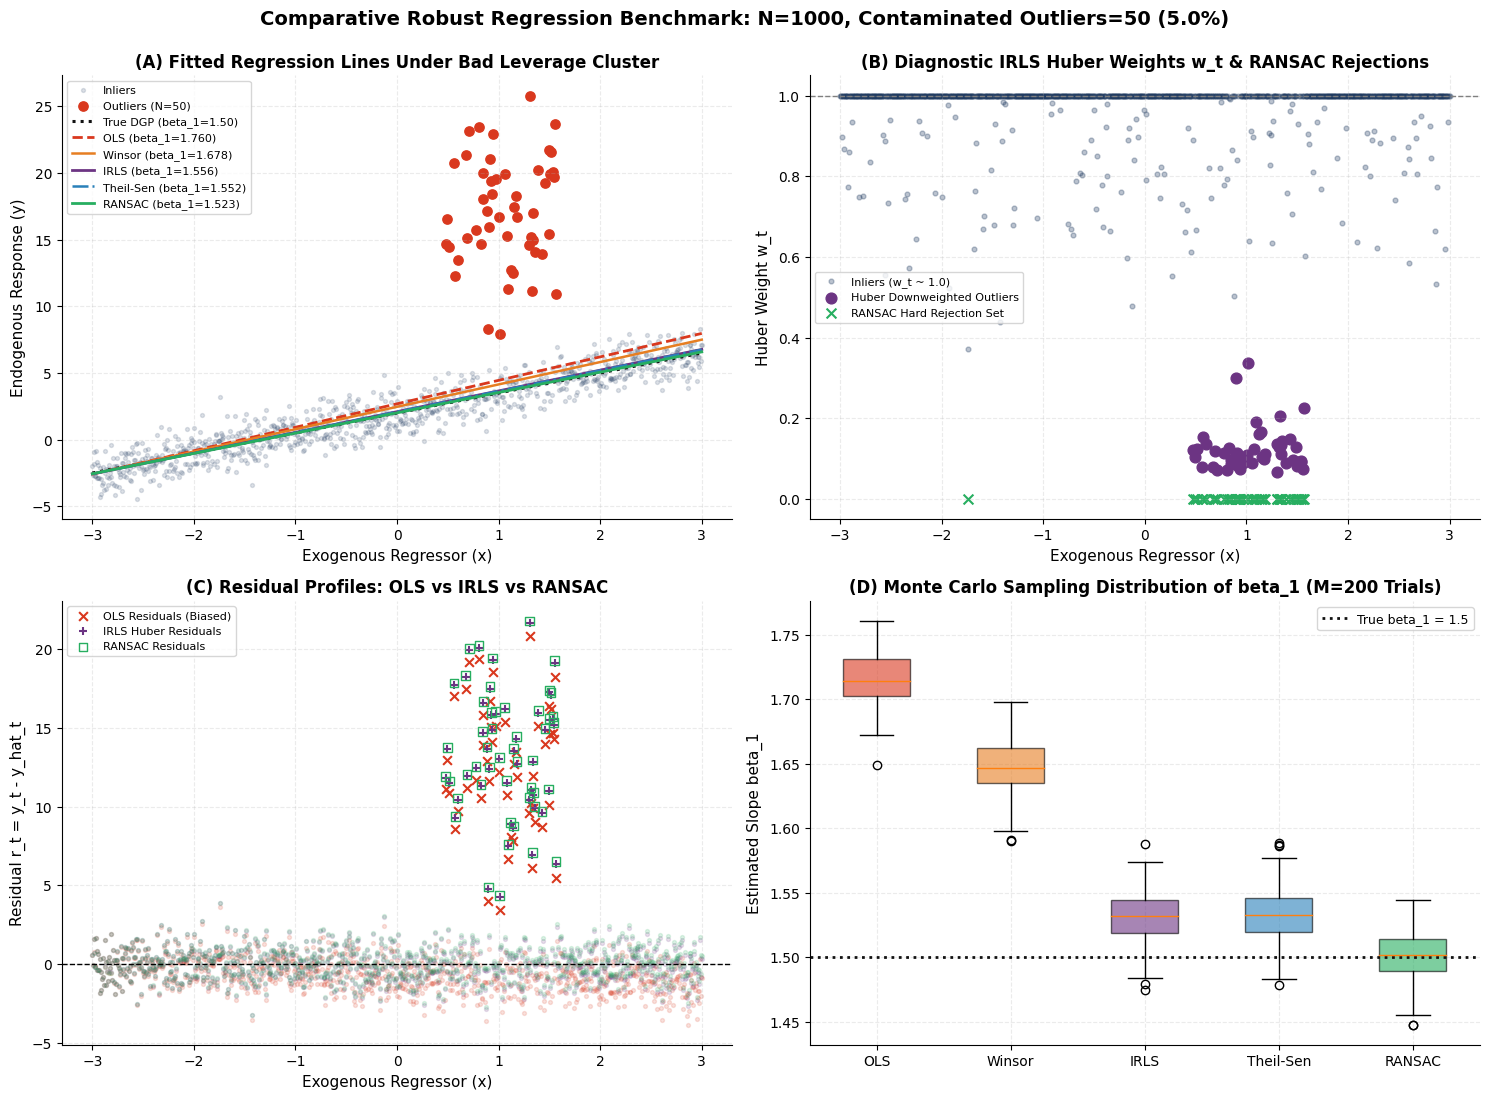

In [5]:
# ------------------------------------------------------------------------------
# Monte Carlo Simulation (M = 200 independent trials)
# ------------------------------------------------------------------------------
M_SIM = 200
mc_results = {'OLS': [], 'Winsor': [], 'IRLS': [], 'Theil-Sen': [], 'RANSAC': []}

mc_rng = np.random.default_rng(101)
for m in range(M_SIM):
    e_m = mc_rng.normal(0, 1, N)
    y_m = BETA0_TRUE + BETA1_TRUE * x + e_m
    c_idx = mc_rng.choice(candidate_idx, N_OUT, replace=False)
    y_m[c_idx] = (BETA0_TRUE + BETA1_TRUE * x[c_idx] + out_y_offset + mc_rng.normal(0, out_y_spread, N_OUT))
    
    # OLS fit
    b_ols_m = np.linalg.lstsq(X, y_m, rcond=None)[0]
    mc_results['OLS'].append(b_ols_m[1])
    
    # Winsorized OLS fit
    b_win_m, _ = fit_winsorized_ols(x, y_m)
    mc_results['Winsor'].append(b_win_m[1])
    
    # IRLS Huber fit
    b_irls_m, _, _ = fit_irls_huber(X, y_m)
    mc_results['IRLS'].append(b_irls_m[1])
    
    # Theil-Sen fit
    b_ts_m = fit_theil_sen(x, y_m, max_pairs=30000, rng_seed=m)
    mc_results['Theil-Sen'].append(b_ts_m[1])
    
    # RANSAC fit
    b_ran_m, _, _ = fit_ransac(X, y_m, n_iter=300, rng_seed=m)
    mc_results['RANSAC'].append(b_ran_m[1])

df_mc = pd.DataFrame(mc_results)

# ------------------------------------------------------------------------------
# 4-Panel Visualization
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
x_grid = np.linspace(x.min(), x.max(), 300)

# PANEL A: Fitted Regression Lines
ax = axes[0, 0]
ax.scatter(x[~is_out], y_dirty[~is_out], color=COLORS['clean'], alpha=0.15, s=8, label='Inliers')
ax.scatter(x[is_out], y_dirty[is_out], color=COLORS['outlier'], s=45, label=f'Outliers (N={N_OUT})')
ax.plot(x_grid, BETA0_TRUE + BETA1_TRUE * x_grid, color=COLORS['true'], lw=2.2, ls=':', label=f'True DGP (beta_1={BETA1_TRUE:.2f})')
ax.plot(x_grid, b0_ols + b1_ols * x_grid, color=COLORS['ols'], lw=2, ls='--', label=f'OLS (beta_1={b1_ols:.3f})')
ax.plot(x_grid, b0_win + b1_win * x_grid, color=COLORS['winsor'], lw=1.8, label=f'Winsor (beta_1={b1_win:.3f})')
ax.plot(x_grid, b0_irls + b1_irls * x_grid, color=COLORS['irls'], lw=2, label=f'IRLS (beta_1={b1_irls:.3f})')
ax.plot(x_grid, b0_ts + b1_ts * x_grid, color=COLORS['theilsen'], lw=1.8, ls='-.', label=f'Theil-Sen (beta_1={b1_ts:.3f})')
ax.plot(x_grid, b0_ransac + b1_ransac * x_grid, color=COLORS['ransac'], lw=2, ls='-', label=f'RANSAC (beta_1={b1_ransac:.3f})')
ax.set_title('(A) Fitted Regression Lines Under Bad Leverage Cluster', fontweight='bold')
ax.set_xlabel('Exogenous Regressor (x)')
ax.set_ylabel('Endogenous Response (y)')
ax.legend(fontsize=8, loc='upper left')

# PANEL B: IRLS Weights & RANSAC Classification
ax = axes[0, 1]
ax.scatter(x[~is_out], w_final[~is_out], color=COLORS['clean'], alpha=0.3, s=12, label='Inliers (w_t ~ 1.0)')
ax.scatter(x[is_out], w_final[is_out], color=COLORS['irls'], s=60, marker='o', label='Huber Downweighted Outliers')
ransac_flagged = ~inliers_ransac
ax.scatter(x[ransac_flagged], np.zeros(np.sum(ransac_flagged)), color=COLORS['ransac'], marker='x', s=50, lw=1.5, label='RANSAC Hard Rejection Set')
ax.axhline(1.0, color='gray', ls='--', lw=1)
ax.set_title('(B) Diagnostic IRLS Huber Weights w_t & RANSAC Rejections', fontweight='bold')
ax.set_xlabel('Exogenous Regressor (x)')
ax.set_ylabel('Huber Weight w_t')
ax.legend(fontsize=8, loc='center left')

# PANEL C: Residual Scatter Profiles
ax = axes[1, 0]
ax.scatter(x[~is_out], r_ols[~is_out], color=COLORS['ols'], alpha=0.15, s=8)
ax.scatter(x[is_out], r_ols[is_out], color=COLORS['ols'], s=40, marker='x', label='OLS Residuals (Biased)')
ax.scatter(x[~is_out], r_irls[~is_out], color=COLORS['irls'], alpha=0.15, s=8)
ax.scatter(x[is_out], r_irls[is_out], color=COLORS['irls'], s=40, marker='+', label='IRLS Huber Residuals')
ax.scatter(x[~is_out], r_ransac[~is_out], color=COLORS['ransac'], alpha=0.15, s=8)
ax.scatter(x[is_out], r_ransac[is_out], color=COLORS['ransac'], s=40, marker='s', facecolors='none', label='RANSAC Residuals')
ax.axhline(0, color='black', ls='--', lw=1)
ax.set_title('(C) Residual Profiles: OLS vs IRLS vs RANSAC', fontweight='bold')
ax.set_xlabel('Exogenous Regressor (x)')
ax.set_ylabel('Residual r_t = y_t - y_hat_t')
ax.legend(fontsize=8, loc='upper left')

# PANEL D: Monte Carlo Slope Distribution Boxplot
ax = axes[1, 1]
box_data = [df_mc['OLS'], df_mc['Winsor'], df_mc['IRLS'], df_mc['Theil-Sen'], df_mc['RANSAC']]
bp = ax.boxplot(box_data, labels=['OLS', 'Winsor', 'IRLS', 'Theil-Sen', 'RANSAC'], patch_artist=True)
box_colors = [COLORS['ols'], COLORS['winsor'], COLORS['irls'], COLORS['theilsen'], COLORS['ransac']]
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.axhline(BETA1_TRUE, color=COLORS['true'], ls=':', lw=2, label=f'True beta_1 = {BETA1_TRUE}')
ax.set_title(f'(D) Monte Carlo Sampling Distribution of beta_1 (M={M_SIM} Trials)', fontweight='bold')
ax.set_ylabel('Estimated Slope beta_1')
ax.legend(fontsize=9, loc='upper right')

plt.suptitle(f'Comparative Robust Regression Benchmark: N={N}, Contaminated Outliers={N_OUT} (5.0%)', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


## PART 2: Adaptive Online Estimation

In quantitative trading strategies (such as statistical arbitrage, **Pairs Trading cointegration hedge ratios**, and dynamic market-making), data arrives sequentially, and parameter relations drift over time.
Quantitative systems require online algorithms that satisfy two competing objectives:
1. **Adaptivity:** Rapidly update parameters when true structural market changes occur.
2. **Robustness:** Reject micro-structural market noise, flash crashes, and transient data recording errors.

---

### Rolling OLS
Re-estimates OLS on trailing observations $\{(x_i, y_i)\}_{i=t-W}^{t-1}$.
* **The Window-Exit Shock:** An anomaly receives full $1/W$ weight upon entry and pollutes the hedge ratio for $W$ steps. When it drops out of the window, a second abrupt and spurious parameter jump occurs.

---

### Kalman Filter
Models time-varying regression coefficients $\theta_t = [\beta_{0,t}, \beta_{1,t}]^T$ as unobserved latent states:

$$\theta_t = \theta_{t-1} + w_t, \quad w_t \sim \mathcal{N}(0, Q)$$

$$y_t = H_t \theta_t + v_t, \quad v_t \sim \mathcal{N}(0, R), \quad H_t = [1, \; x_t]$$

* **Limitation:** The measurement innovation $\nu_t = y_t - H_t \hat{\theta}_t^-$ updates the state linearly through the Kalman gain $K_t$. It lacks an endogenous outlier-rejection mechanism; setting $Q \approx 0$ suppresses outlier impact only by sacrificing adaptivity entirely.

---

### Robust Kalman Filter
Combines real-time dynamic tracking with an **M-estimator dampening rule on the normalized innovation**:
1. Compute standardized innovation:

   $$s_t = \frac{|\nu_t|}{\sqrt{S_t}}, \quad S_t = H_t P_t^- H_t^T + R$$

2. Compute the Huber attenuation factor:

   $$\psi_t = \begin{cases} 1 & \text{if } s_t \leq k \\ \frac{k}{s_t} & \text{if } s_t > k \end{cases}$$

3. **Robust State Update:** Attenuate the innovation before state correction: $\nu_t^* = \psi_t \cdot \nu_t$. Under regular observations, $\psi_t = 1.0$ (100% standard Kalman efficiency); during outliers, impact is bounded linearly.




Rolling OLS Final beta_1: 0.5978
Standard Kalman Final beta_1: 1.3593
Robust Kalman Final beta_1: 1.5067 (True Value: 1.5000)


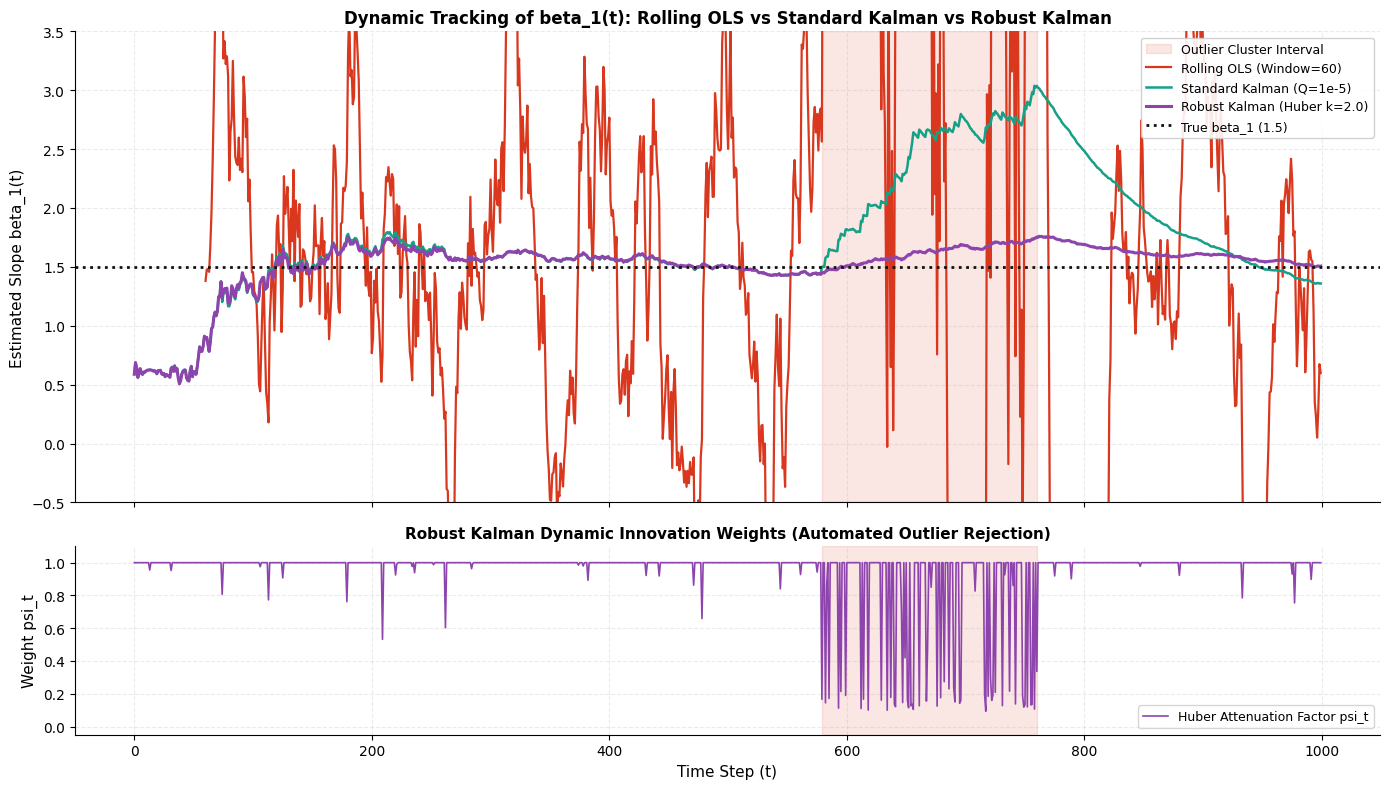

In [6]:
# ------------------------------------------------------------------------------
# 5.1 Rolling OLS
# ------------------------------------------------------------------------------
def rolling_ols(x_arr, y_arr, window=60):
    n = len(x_arr)
    b0_path = np.full(n, np.nan)
    b1_path = np.full(n, np.nan)
    for t in range(window, n):
        xs = x_arr[t-window:t]
        ys = y_arr[t-window:t]
        v_x = np.var(xs)
        if v_x > 1e-12:
            b1 = np.cov(xs, ys, bias=True)[0, 1] / v_x
            b0 = ys.mean() - b1 * xs.mean()
            b0_path[t] = b0
            b1_path[t] = b1
    return b0_path, b1_path

# ------------------------------------------------------------------------------
# 5.2 Standard Kalman Filter
# ------------------------------------------------------------------------------
def kalman_filter(x_arr, y_arr, Q_scale=1e-5, R_val=1.0):
    n = len(x_arr)
    theta = np.array([0.0, 0.0])  # Prior state initialization
    P = np.eye(2) * 5.0           # Initial state covariance
    Q = np.eye(2) * Q_scale       # Process noise covariance
    
    b0_path = np.zeros(n)
    b1_path = np.zeros(n)
    
    for t in range(n):
        Ht = np.array([[1.0, x_arr[t]]])
        
        # Prediction step
        theta_pred = theta
        P_pred = P + Q
        
        # Innovation step
        nu = y_arr[t] - (Ht @ theta_pred)[0]
        S = (Ht @ P_pred @ Ht.T + R_val)[0, 0]
        
        # Gain and State Update
        K = (P_pred @ Ht.T) / S
        theta = theta_pred + K.flatten() * nu
        P = (np.eye(2) - K @ Ht) @ P_pred
        
        b0_path[t] = theta[0]
        b1_path[t] = theta[1]
        
    return b0_path, b1_path

# ------------------------------------------------------------------------------
# 5.3 Robust Kalman Filter (Huber-Dampened Innovation)
# ------------------------------------------------------------------------------
def robust_kalman_filter(x_arr, y_arr, Q_scale=1e-5, R_val=1.0, k_huber=2.0):
    n = len(x_arr)
    theta = np.array([0.0, 0.0])
    P = np.eye(2) * 5.0
    Q = np.eye(2) * Q_scale
    
    b0_path = np.zeros(n)
    b1_path = np.zeros(n)
    weights_path = np.zeros(n)
    
    for t in range(n):
        Ht = np.array([[1.0, x_arr[t]]])
        
        # Prediction step
        theta_pred = theta
        P_pred = P + Q
        
        # Innovation step
        nu = y_arr[t] - (Ht @ theta_pred)[0]
        S = (Ht @ P_pred @ Ht.T + R_val)[0, 0]
        
        # Standardized innovation and Huber attenuation
        s_std = np.abs(nu) / np.sqrt(S)
        psi = 1.0 if s_std <= k_huber else (k_huber / s_std)
        weights_path[t] = psi
        
        # Robust Update step
        K = (P_pred @ Ht.T) / S
        theta = theta_pred + K.flatten() * (psi * nu)
        P = (np.eye(2) - K @ Ht) @ P_pred
        
        b0_path[t] = theta[0]
        b1_path[t] = theta[1]
        
    return b0_path, b1_path, weights_path

WINDOW = 60
b0_roll, b1_roll = rolling_ols(x, y_dirty, window=WINDOW)
b0_kal, b1_kal = kalman_filter(x, y_dirty, Q_scale=1e-5, R_val=1.0)
b0_rkal, b1_rkal, k_weights = robust_kalman_filter(x, y_dirty, Q_scale=1e-5, R_val=1.0, k_huber=2.0)

print(f"Rolling OLS Final beta_1: {b1_roll[-1]:.4f}")
print(f"Standard Kalman Final beta_1: {b1_kal[-1]:.4f}")
print(f"Robust Kalman Final beta_1: {b1_rkal[-1]:.4f} (True Value: {BETA1_TRUE:.4f})")

# Visualization: Adaptive Time-Series Tracking Comparison
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1.2]})

out_start, out_end = out_idx.min(), out_idx.max()
ax1.axvspan(out_start, out_end, color=COLORS['outlier'], alpha=0.12, label='Outlier Cluster Interval')

ax1.plot(b1_roll, color=COLORS['ols'], lw=1.6, label=f'Rolling OLS (Window={WINDOW})')
ax1.plot(b1_kal, color=COLORS['kalman'], lw=1.8, label='Standard Kalman (Q=1e-5)')
ax1.plot(b1_rkal, color=COLORS['robust_kalman'], lw=2.2, label='Robust Kalman (Huber k=2.0)')
ax1.axhline(BETA1_TRUE, color=COLORS['true'], ls=':', lw=2, label=f'True beta_1 ({BETA1_TRUE})')

ax1.set_title('Dynamic Tracking of beta_1(t): Rolling OLS vs Standard Kalman vs Robust Kalman', fontweight='bold')
ax1.set_ylabel('Estimated Slope beta_1(t)')
ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
ax1.set_ylim(-0.5, 3.5)

# Subplot: Huber attenuation weights assigned in real time
ax2.plot(k_weights, color=COLORS['robust_kalman'], lw=1.2, label='Huber Attenuation Factor psi_t')
ax2.axvspan(out_start, out_end, color=COLORS['outlier'], alpha=0.12)
ax2.set_title('Robust Kalman Dynamic Innovation Weights (Automated Outlier Rejection)', fontweight='bold', fontsize=11)
ax2.set_xlabel('Time Step (t)')
ax2.set_ylabel('Weight psi_t')
ax2.set_ylim(-0.05, 1.1)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()


## Conclusions

### Summary of Empirical Findings
1. **OLS Fails Under Leverage Clusters:**  
   Even a modest 5.0% localized bad-leverage cluster inflates the slope from $\beta_1 = 1.50$ to $1.76$, substantially deteriorating clean out-of-sample prediction ($RMSE_{\text{clean}} = 1.248$ vs $0.974$).
2. **Winsorized OLS (MAD):**  
   Provides rapid, computationally lightweight filtering suitable for cross-sectional factor ranking, but remains vulnerable when vertical anomalies align with extreme leverage coordinates.
3. **IRLS with Huber Loss:**  
   Delivers near-optimal parameter recovery ($\|\hat{\beta} - \beta^*\|_2 \approx 0.11$) while preserving 95% efficiency. It represents the best general-purpose static robust estimator.
4. **Theil-Sen & RANSAC:**  
   Provide unmatched empirical resistance against high-breakdown contamination. RANSAC achieves near-perfect parameter recovery ($\|\hat{\beta} - \beta^*\|_2 = 0.026$) by isolating the true linear manifold.
5. **Time-Series Streaming Dominance of Robust Kalman:**  
   Rolling OLS suffers from catastrophic window-exit volatility. Standard Kalman slowly incorporates anomalous observations. The **Robust Kalman Filter**, by dynamically dampening non-Gaussian innovations, maintains accurate tracking throughout the outlier shock.

---

### Quantitative Practitioner Decision Flowchart

```
                          PROBLEM TYPE
                               │
        ┌──────────────────────┴──────────────────────┐
        ▼                                             ▼
STATIC / CROSS-SECTIONAL                       DYNAMIC / STREAMING
        │                                             │
   High Leverage Present?                     Stationary Parameters?
   ├── NO  ──► IRLS (Huber) / MAD Winsor       ├── YES ──► Kalman Filter (Small Q)
   └── YES ──► RANSAC / Theil-Sen              └── NO  ──► Robust Kalman Filter (Huber)
```
